In [4]:
##Imports
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
import itertools
from torch.nn import Parameter

import torch
import torch.fft as fft
import torchoptics
from torchoptics.profiles import gaussian, circle
from torchoptics.elements import PhaseModulator
from torchoptics import Field, System
from pyhank import HankelTransform

device = "cuda" if torch.cuda.is_available() else "cpu"

1st part: create a lens by reducing the problem to 1d thanks to the radial simmetry

In [1]:
# ==========================================
# PROGRAM 1: FUNCTIONS & INITIALIZATION
# ==========================================

def KtoR(k, waveLength, focalLength):
    return waveLength * focalLength * k / (2 * np.pi)


def RtoK(r, waveLength, focalLength):
    return 2 * np.pi * r / (waveLength * focalLength)


def MSE_w(goalProfile, iterProfile, weights):
    return np.sum(weights * (goalProfile - iterProfile) ** 2) / (np.sum(weights * goalProfile ** 2) + 1e-15)


def GerchbergSaxton(inputProfile, goalFunction, transformer, initial_doe, radius=100, maxiter=10000, errMin=1e-4,
                    initialSlope=8):
    N = len(goalFunction)
    r = transformer.r
    kr = transformer.kr

    P_in = 2 * np.pi * np.trapz(np.abs(inputProfile) ** 2 * r, r)
    P_goal = 2 * np.pi * np.trapz(np.abs(goalFunction) ** 2 * r, r)
    goalProfile = goalFunction * np.sqrt(P_in / P_goal)
    n = 2

    if len(initial_doe) == 0:
        testfit = np.array(
            [initialSlope * item * 1e2 * (item * 1e2) ** n / ((item * 1e2) ** n + 1) - 2.5 for item in r])
        U_DOE = np.exp(1j * testfit)
    else:
        U_DOE = initial_doe

    U_initial = transformer.qdht(inputProfile)
    weights = kr * np.gradient(kr)

    P_in = np.sum(weights * np.abs(U_initial) ** 2)
    P_goal = np.sum(weights * np.abs(goalFunction) ** 2)
    goalProfile = goalFunction * np.sqrt(P_in / P_goal)

    adaptive_goal = np.copy(goalProfile)

    for i in range(maxiter):
        U_tot = inputProfile * U_DOE
        U_image = transformer.qdht(U_tot)
        U_im_abs = np.abs(U_image)
        I_found = U_im_abs ** 2

        error = MSE_w(goalProfile, U_im_abs, weights)
        adaptive_goal = adaptive_goal + 0.5 * (goalProfile - U_im_abs)
        adaptive_goal[adaptive_goal < 0] = 0
        U_image = adaptive_goal * np.exp(1j * np.angle(U_image))

        if error < errMin:
            break

        U_DOE = transformer.iqdht(U_image)
        U_DOE = np.exp(1j * np.angle(U_DOE))

    return U_DOE


def wrap(angles):
    return (angles + np.pi) % (2 * np.pi) - np.pi


class GS_DOE:
    def __init__(self, params):
        self.setParams(params)

    def setParams(self, params):
        self.fl = params["fl"]
        self.wl = params["wl"]
        self.rmax = params["rmax"]
        self.N = params["N"]
        self.w0 = params["w0"]
        self.wgoal = params["wgoal"]

    def makeProfiles(self, p=3):
        self.transformer = HankelTransform(order=0, max_radius=self.rmax, n_points=self.N)
        self.r = self.transformer.r
        self.kr = self.transformer.kr
        self.inputAmp = np.exp(-(self.r / self.w0) ** 2)
        self.rho = self.wl * self.fl * self.transformer.kr / (2 * np.pi)
        self.goalProfile = np.exp(-(self.rho / self.wgoal) ** (2 * p))

    def makeDOE(self, initial_doe, initialSlope=8, maxiter=1000, errMin=1e-4):
        self.initialSlope = initialSlope
        self.DOE = GerchbergSaxton(self.inputAmp, self.goalProfile, self.transformer, initial_doe, radius=self.rmax,
                                   maxiter=maxiter,
                                   errMin=errMin, initialSlope=initialSlope)

    def getDOE(self):
        return self.DOE

From a radius, create the lenses by using different 'interpolation techniques'

In [5]:

def radial_to_2d(profile, radial_grid, N, rmax):

    shape = 2 * N - 1

    # Must match the spacing used by the PyTorch propagation
    dx = rmax / N

    coords = (
        np.arange(shape) - (shape - 1) / 2
    ) * dx

    X, Y = np.meshgrid(coords, coords, indexing='ij')

    R = np.sqrt(X**2 + Y**2)

    # Interpolate using the actual QDHT radial coordinates
    profile_2d = np.interp(
        R.ravel(),
        radial_grid,
        profile,
        left=profile[0],
        right=profile[-1]
    ).reshape(shape, shape)

    return profile_2d

def genLensPhase(N, wl, fl, dx):
    y, x = np.ogrid[-(N - 1):N, -(N - 1):N]
    r = np.sqrt(x ** 2 + y ** 2) * dx
    return -np.pi * r ** 2 / (wl * fl)


def create_interspersed_doe(DOEs: list, mirror: bool = False):
    DOEs = [np.asarray(doe) for doe in DOEs]
    n = len(DOEs)
    radius_len = len(DOEs[0])
    g = 2 * radius_len
    merged_radius = np.zeros(radius_len)

    for r in range(radius_len):
        if mirror:
            cycle_len = 2 * n
            rem = r % cycle_len
            lens_idx = rem if rem < n else (cycle_len - 1 - rem)
        else:
            lens_idx = r % n
        profile = DOEs[lens_idx]
        merged_radius[r] = profile[r] if r < len(profile) else profile[-1]

    center = (g - 1) / 2.0
    y, x = np.ogrid[:g, :g]
    r_grid = np.sqrt((x - center) ** 2 + (y - center) ** 2)
    r_indices = np.round(r_grid).astype(int)
    r_indices = np.clip(r_indices, 0, radius_len - 1)
    doe_grid = merged_radius[r_indices]
    return merged_radius, doe_grid


def create_permuted_sector_doe(DOEs: list, a: float):
    DOEs = [np.asarray(doe) for doe in DOEs]
    n = len(DOEs)
    radius_len = len(DOEs[0])
    padded_DOEs = []
    for doe in DOEs:
        if len(doe) < radius_len:
            padded_DOEs.append(np.pad(doe, (0, radius_len - len(doe)), mode='edge'))
        else:
            padded_DOEs.append(doe[:radius_len])

    orig_stack = np.vstack(padded_DOEs)
    perms = list(itertools.permutations(range(n)))
    num_perms = len(perms)
    r_idx = np.arange(radius_len)
    base_lens_indices = r_idx % n

    aux_DOEs = []
    for p in perms:
        p_array = np.array(p)
        permuted_lens_indices = p_array[base_lens_indices]
        aux_radius = orig_stack[permuted_lens_indices, r_idx]
        aux_DOEs.append(aux_radius)

    num_sectors_exact = 360.0 / a
    num_sectors = int(np.round(num_sectors_exact))
    g = 2 * radius_len
    center = (g - 1) / 2.0
    y, x = np.ogrid[:g, :g]

    r_grid = np.sqrt((x - center) ** 2 + (y - center) ** 2)
    r_indices = np.clip(np.round(r_grid).astype(int), 0, radius_len - 1)

    theta_grid = np.arctan2(y - center, x - center)
    theta_deg = np.degrees(theta_grid) % 360

    sector_idx = np.clip(np.floor(theta_deg / a).astype(int), 0, num_sectors - 1)
    aux_idx = sector_idx % num_perms
    aux_stack = np.vstack(aux_DOEs)
    doe_grid = aux_stack[aux_idx, r_indices]
    return doe_grid

Create and show the lenses

Generating baseline 1D GS DOEs...


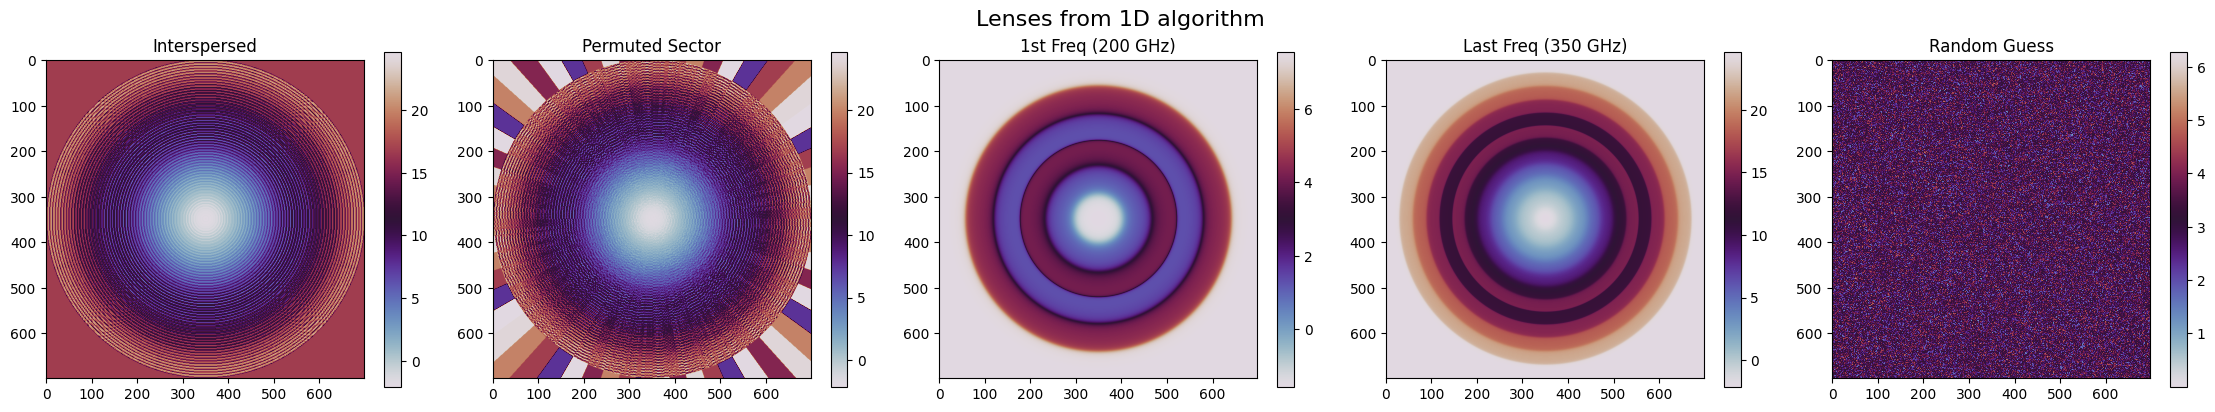

In [6]:

# ---------------------------------------------
# Generate Initial 1D Profiles 
# ---------------------------------------------
print("Generating baseline 1D GS DOEs...")
f0 = 200 * 1e9
does = []
radial_grid = None
for i in range(0, 6, 1):
    f = f0 + i * 30 * 1e9
    initial_doe = []
    params = {
        "fl": 15e-2,  # meters
        "wl": 3e8 / f,  # meters
        "rmax": 10e-2,  # meters
        "N": 350,
        "w0": 0.02,  # meters
        "wgoal": 0.008  # meters
    }
    DOE_maker = GS_DOE(params)
    DOE_maker.makeProfiles(p=4)
    DOE_maker.makeDOE(initial_doe, initialSlope=4, maxiter=250)
    does.append(np.unwrap(np.angle(DOE_maker.getDOE())))
    
    if radial_grid is None:
        radial_grid = DOE_maker.r.copy()
# Get specific 2D DOEs for PyTorch Initialization
_, prova1 = create_interspersed_doe(does)
prova1 = prova1[:-1, :-1]  # Crop to 699x699

prova3 = create_permuted_sector_doe(does, 360 / 1440)
prova3 = prova3[:-1, :-1]

does_0_2d = radial_to_2d(
    does[0],
    radial_grid,
    N=350,
    rmax=0.1
)
does_end_2d = radial_to_2d(
    does[-1],
    radial_grid,
    N=350,
    rmax=0.1
)

# --- NEW: Generate Random Phase Lens ---
shape_2d = 2 * params['N'] - 1
random_doe_2d = np.random.uniform(0, 2 * np.pi, size=(shape_2d, shape_2d))

# Lists to iterate for optimization (Added Random Lens)
initial_DOEs = [prova1, prova3, does_0_2d, does_end_2d, random_doe_2d]
titles = ["Interspersed", "Permuted Sector", "1st Freq (200 GHz)", "Last Freq (350 GHz)", "Random Guess"]

# 1. Plot the Final Optimized Lens Phases (Dynamic width based on number of items)
num_lenses = len(titles)
fig1, axes1 = plt.subplots(1, num_lenses, figsize=(4.5 * num_lenses, 4))
for ax, phase, title in zip(axes1, initial_DOEs, titles):
    im = ax.imshow(phase, cmap='twilight')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
fig1.suptitle("Lenses from 1D algorithm", fontsize=16)
plt.tight_layout()
plt.show()


2nd part: 2d algorithm to optimize without symetry

In [9]:
# ==========================================
# PROGRAM 2: PYTORCH MULTI-FREQUENCY OPTIMIZATION
# ==========================================
print("\nStarting multi-frequency PyTorch Optimization...")
dx = params['rmax'] / params['N']
shape = 2 * params['N'] - 1

torchoptics.set_default_spacing(dx)

# FIX 1: Explicitly cast the optics profiles to float32
source_profile = gaussian(shape, waist_radius=params['w0']).to(device, dtype=torch.float32)
target_profile = circle(shape, radius=params['wgoal']).to(device, dtype=torch.float32)
target_mask = (target_profile > 0).to(torch.float32)

# Match target power explicitly to incident beam to create standard MSE loss target
P_in = torch.sum(torch.abs(source_profile) ** 2)
P_tgt = torch.sum(target_mask)
I_tgt = (target_mask * (P_in / P_tgt)).to(torch.float32)

# Precalculate frequencies and their forward propagation Transfer Functions
frequencies = [f0 + i * 30 * 1e9 for i in range(6)]
H_fws = []

# FIX 2: Ensure frequency grids are float32
fx = fft.fftfreq(shape, d=dx, device=device).to(torch.float32)
fy = fft.fftfreq(shape, d=dx, device=device).to(torch.float32)
FX, FY = torch.meshgrid(fx, fy, indexing='ij')

for f in frequencies:
    lam_f = 3e8 / f
    term = 1 - (lam_f * FX) ** 2 - (lam_f * FY) ** 2
    mask = term >= 0
    phase_term = 2 * torch.pi * params['fl'] / lam_f * torch.sqrt(torch.clamp(term, min=0))
    # FIX 3: Cast the transfer function to complex64
    H_fws.append((torch.exp(1j * phase_term.to(torch.float32)) * mask).to(torch.complex64))

# Store results
optimized_phases = []
optimized_outputs = []

optimized_freq_outputs = []

# ... [Optimization Loop] ...

# --- BASE LENS SUPPRESSED ---
# We no longer calculate or add the geometric focusing phase.
# The DOE parameter 'phi' will have to learn the focusing power entirely on its own.

for init_doe, title in zip(initial_DOEs, titles):
    print(f"Optimizing: {title}")

    # Init PyTorch Parameter (DOE Pattern ONLY)
    initial_phase = torch.tensor(init_doe, device=device, dtype=torch.float32)
    phi = Parameter(initial_phase.clone())

    # We use Adam to optimize the continuous phase
    optimizer = torch.optim.Adam([phi], lr=0.1)

    # You may want to increase this since the optimizer now has to discover
    # the macroscopic Fresnel lens profile from scratch.
    num_iterations = 500

    for it in range(num_iterations):
        optimizer.zero_grad()
        total_loss = 0

        # Loop over ALL frequencies and average the loss
        for f_idx in range(len(frequencies)):
            # FIX 4: Explicitly cast E1 to complex64 to prevent python's '1j' from triggering an upcast
            E1 = (source_profile * torch.exp(1j * phi)).to(torch.complex64)
            E2 = fft.ifft2(fft.fft2(E1) * H_fws[f_idx])

            # FIX 5: Ensure output intensity is float32
            I_out = (torch.abs(E2) ** 2).to(torch.float32)

            # Mean Squared Error Loss
            loss_f = torch.nn.functional.mse_loss(I_out, I_tgt)
            total_loss += loss_f

        loss = total_loss / len(frequencies)
        loss.backward()
        optimizer.step()

        if (it + 1) % 100 == 0:
            print(f"  Iter {it + 1}/{num_iterations} | Mean Freq Loss: {loss.item():.4e}")

    optimized_phases.append(phi.detach().cpu().numpy())

    # Calculate Final Average Intensity AND Per-Frequency Intensity
    avg_I = torch.zeros((shape, shape), device=device, dtype=torch.float32)
    freq_Is = []  # Store individual outputs for this lens

    with torch.no_grad():
        for f_idx in range(len(frequencies)):
            E1 = (source_profile * torch.exp(1j * phi)).to(torch.complex64)
            E2 = fft.ifft2(fft.fft2(E1) * H_fws[f_idx])

            I_f = (torch.abs(E2) ** 2).to(torch.float32)
            freq_Is.append(I_f.cpu().numpy())
            avg_I += I_f

    avg_I /= len(frequencies)
    optimized_outputs.append(avg_I.cpu().numpy())
    optimized_freq_outputs.append(freq_Is)  # Append the list of frequencies for this lens

print("\nOptimization Complete.")


Starting multi-frequency PyTorch Optimization...
Optimizing: Interspersed
  Iter 100/500 | Mean Freq Loss: 2.8119e+04
  Iter 200/500 | Mean Freq Loss: 2.8073e+04
  Iter 300/500 | Mean Freq Loss: 2.8067e+04
  Iter 400/500 | Mean Freq Loss: 2.8067e+04
  Iter 500/500 | Mean Freq Loss: 2.8066e+04
Optimizing: Permuted Sector
  Iter 100/500 | Mean Freq Loss: 2.8119e+04
  Iter 200/500 | Mean Freq Loss: 2.8074e+04
  Iter 300/500 | Mean Freq Loss: 2.8068e+04
  Iter 400/500 | Mean Freq Loss: 2.8067e+04
  Iter 500/500 | Mean Freq Loss: 2.8066e+04
Optimizing: 1st Freq (200 GHz)
  Iter 100/500 | Mean Freq Loss: 2.8112e+04
  Iter 200/500 | Mean Freq Loss: 2.8072e+04
  Iter 300/500 | Mean Freq Loss: 2.8067e+04
  Iter 400/500 | Mean Freq Loss: 2.8066e+04
  Iter 500/500 | Mean Freq Loss: 2.8066e+04
Optimizing: Last Freq (350 GHz)
  Iter 100/500 | Mean Freq Loss: 2.8120e+04
  Iter 200/500 | Mean Freq Loss: 2.8077e+04
  Iter 300/500 | Mean Freq Loss: 2.8068e+04
  Iter 400/500 | Mean Freq Loss: 2.8067e+0

Plot the results


Generating plots...


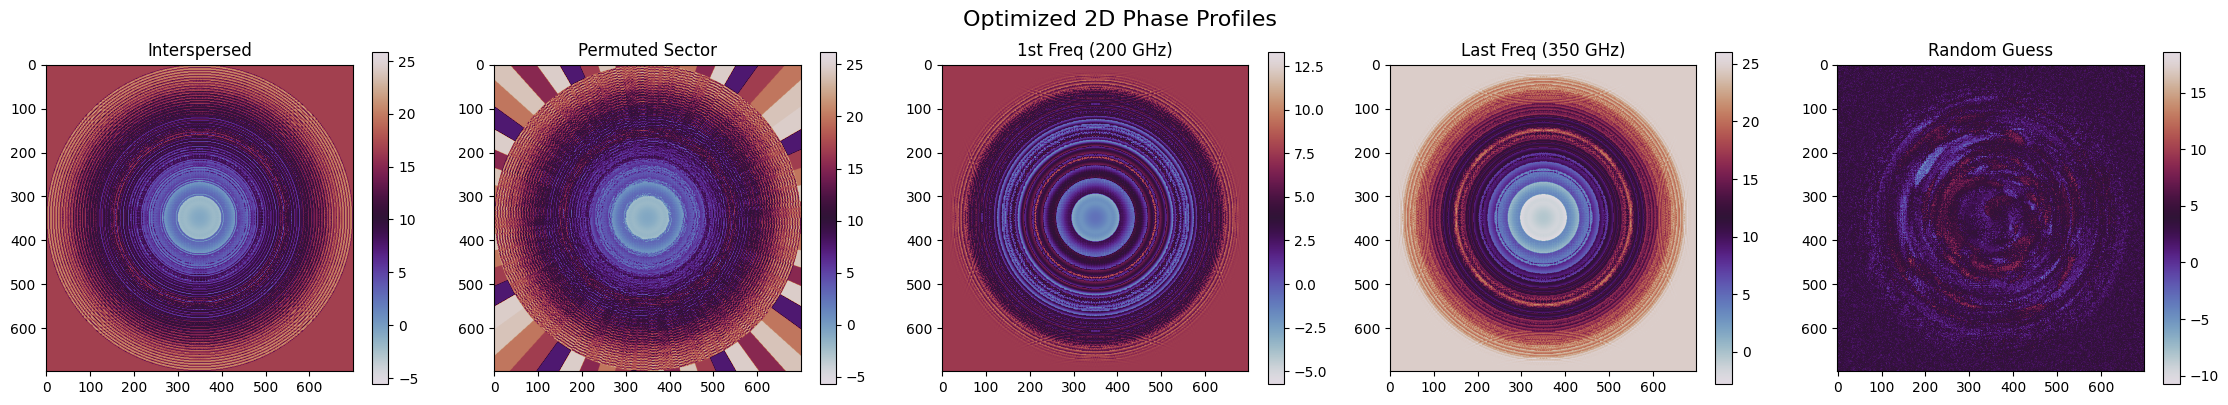

In [10]:
# ==========================================
# PLOTTING RESULTS
# ==========================================

print("\nGenerating plots...")

# 1. Plot the Final Optimized Lens Phases (Dynamic width based on number of items)
num_lenses = len(titles)
fig1, axes1 = plt.subplots(1, num_lenses, figsize=(4.5 * num_lenses, 4))
for ax, phase, title in zip(axes1, optimized_phases, titles):
    im = ax.imshow(phase, cmap='twilight')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
fig1.suptitle("Optimized 2D Phase Profiles", fontsize=16)
plt.tight_layout()
plt.show()

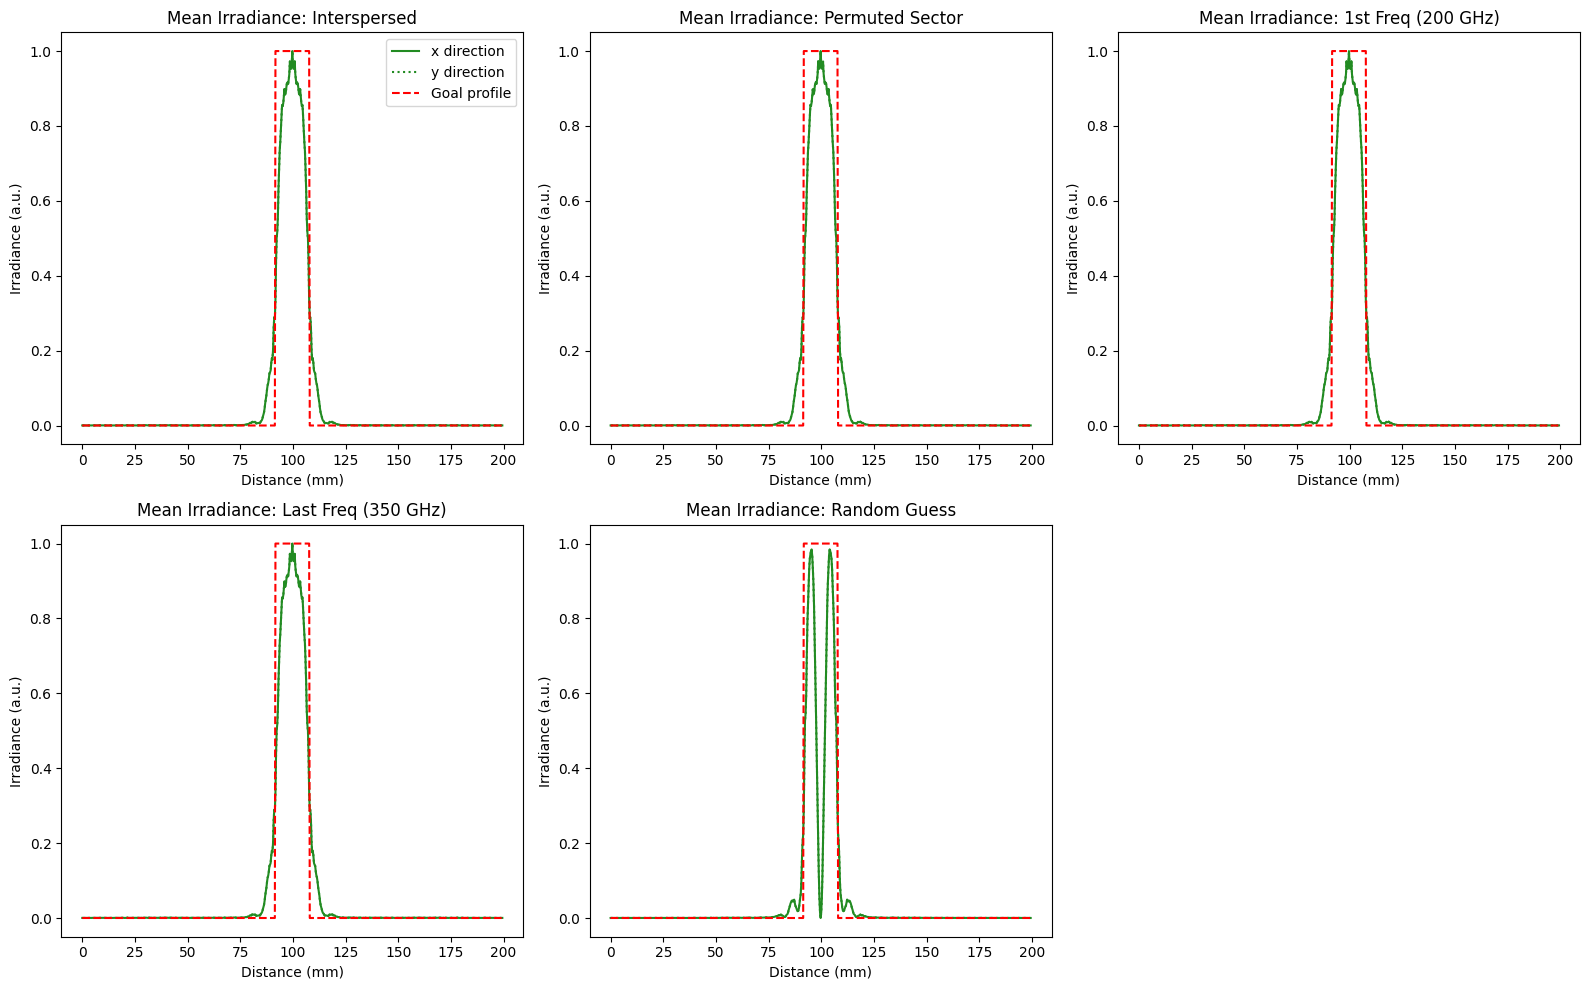

In [11]:
# 2. Plot the Cross-Section Irradiances (Averaged across frequencies in a 2x3 grid)
fig2, axes2 = plt.subplots(2, 3, figsize=(16, 10))
axes2 = axes2.flatten()

# Turn off the empty final axis (since we have 5 items in a 6-slot grid)
for j in range(num_lenses, len(axes2)):
    axes2[j].axis('off')

center_idx = params['N'] - 1
distance_mm = np.arange(shape) * dx * 1000  # meters to mm
center_pos_mm = distance_mm[center_idx]
waist_mm = params["wgoal"] * 1000  # meters to mm
goal_profile = np.where(np.abs(distance_mm - center_pos_mm) <= waist_mm, 1.0, 0.0)

for i, (avg_I, title) in enumerate(zip(optimized_outputs, titles)):
    I_norm = avg_I / np.max(avg_I)
    x_slice = I_norm[center_idx, :]
    y_slice = I_norm[:, center_idx]

    ax = axes2[i]
    ax.plot(distance_mm, x_slice, color='forestgreen', linestyle='-', label='x direction')
    ax.plot(distance_mm, y_slice, color='forestgreen', linestyle=':', label='y direction')
    ax.plot(distance_mm, goal_profile, color='red', linestyle='--', linewidth=1.5, label='Goal profile')

    ax.set_title(f"Mean Irradiance: {title}")
    ax.set_xlabel("Distance (mm)")
    ax.set_ylabel("Irradiance (a.u.)")
    if i == 0:
        ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


Generating per-frequency plots...


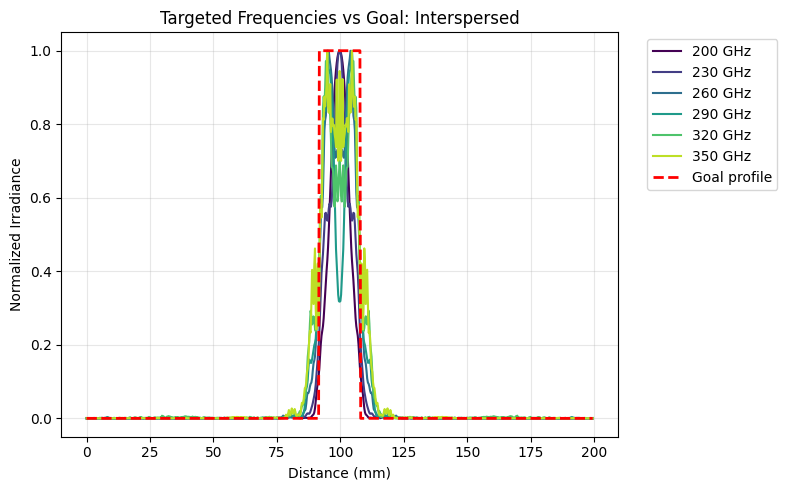

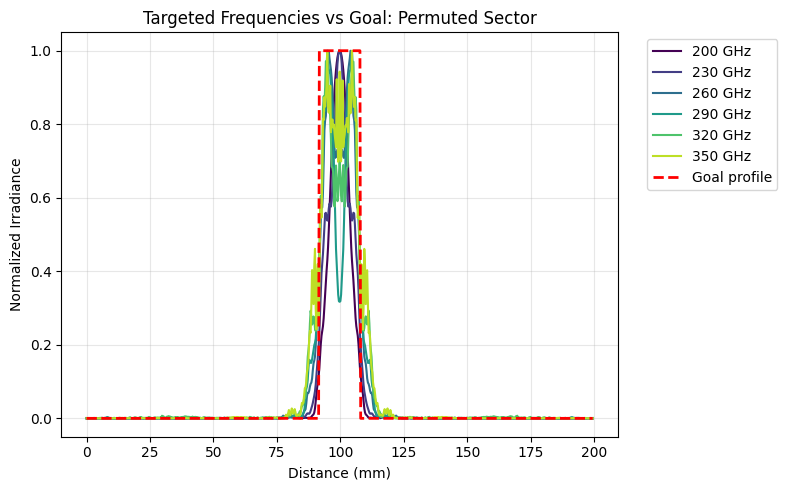

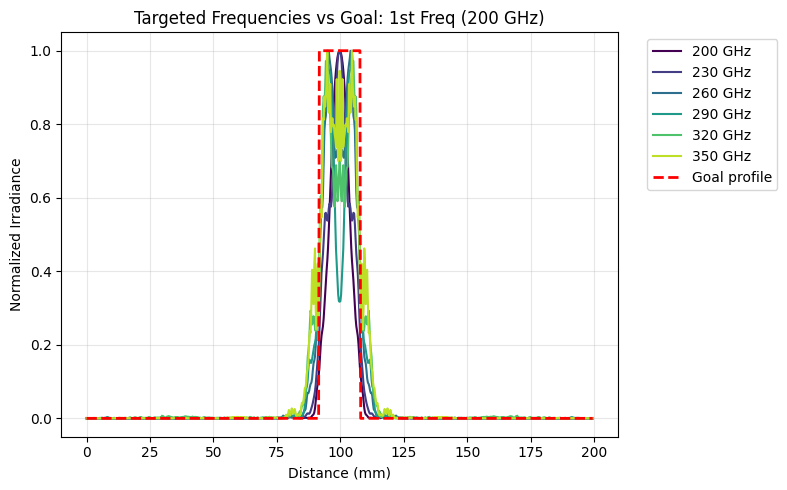

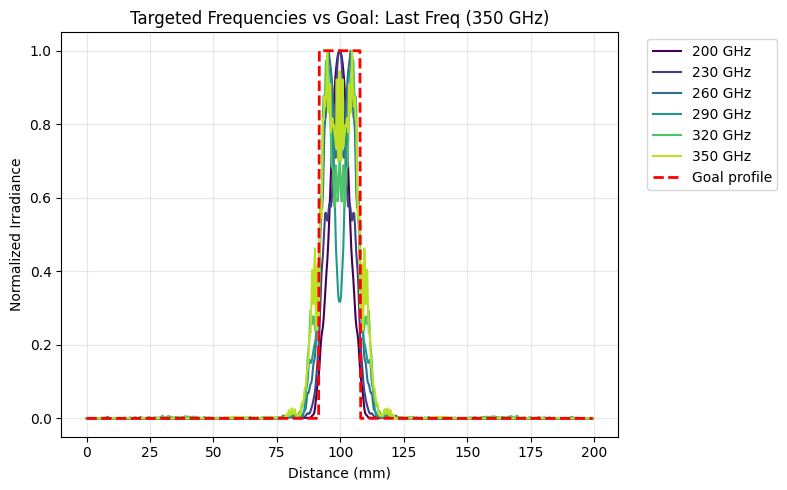

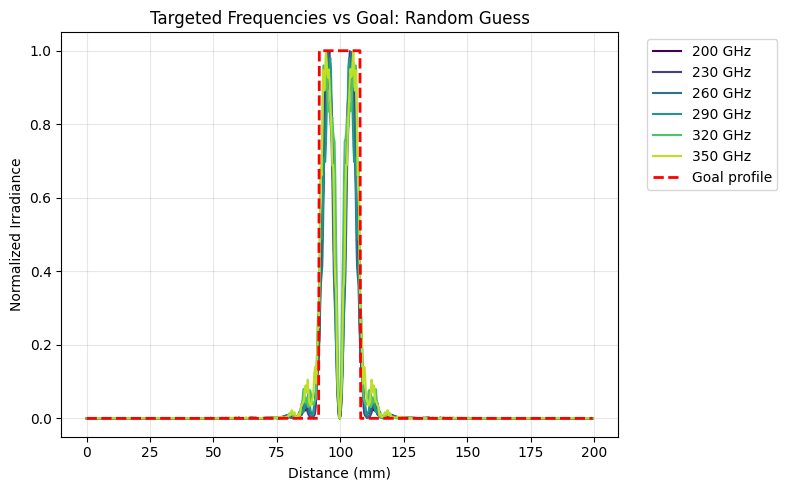

In [12]:
# 3. Plot the Per-Frequency Irradiances for each Lens
# (Requires matplotlib.cm, which is included in standard matplotlib)

print("\nGenerating per-frequency plots...")

for lens_idx, (freq_outputs, title) in enumerate(zip(optimized_freq_outputs, titles)):
    plt.figure(figsize=(8, 5))

    # Generate distinct colors for each frequency using a colormap
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(frequencies)))

    # Plot each frequency's cross-section
    for f_idx, (freq_I, freq_val) in enumerate(zip(freq_outputs, frequencies)):
        I_norm = freq_I / np.max(freq_I)  # Normalize each frequency to its own peak
        x_slice = I_norm[center_idx, :]

        # Using x-slice only to prevent the plot from becoming unreadable with 12+ lines
        plt.plot(distance_mm, x_slice, color=colors[f_idx],
                 label=f'{freq_val / 1e9:.0f} GHz')

    # Plot the Goal Profile
    plt.plot(distance_mm, goal_profile, color='red', linestyle='--',
             linewidth=2, label='Goal profile', zorder=10)

    plt.title(f"Targeted Frequencies vs Goal: {title}")
    plt.xlabel("Distance (mm)")
    plt.ylabel("Normalized Irradiance")

    # Place legend outside the plot so it doesn't cover the beam profile
    plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Option 2: a more complex Loss function that takes into account the different regions of the plane, so can give more weight to the central region, but also assigns different weights to the average over frequencies and to the worse frequency.


Starting multi-frequency PyTorch Optimization...

Optimizing: Interspersed
Iteration 100/100 | Mean Loss: 3.50363e+06 | Worst Loss: 4.11054e+06


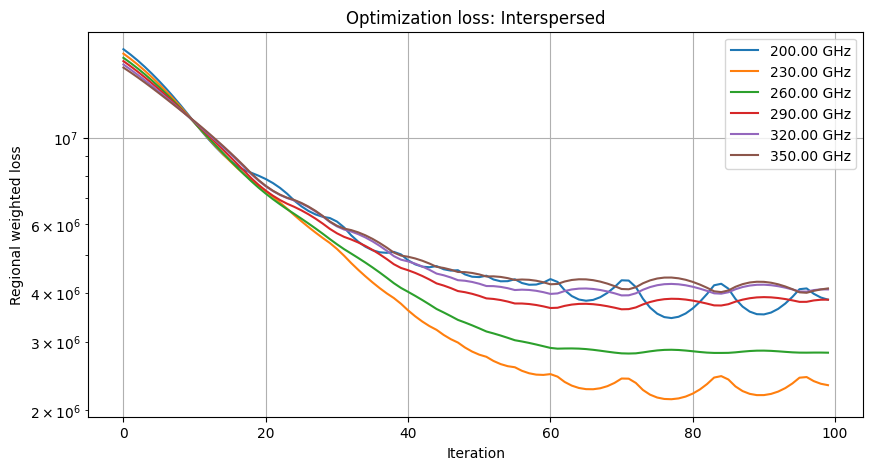


Optimizing: Permuted Sector
Iteration 100/100 | Mean Loss: 3.50987e+06 | Worst Loss: 4.06110e+06


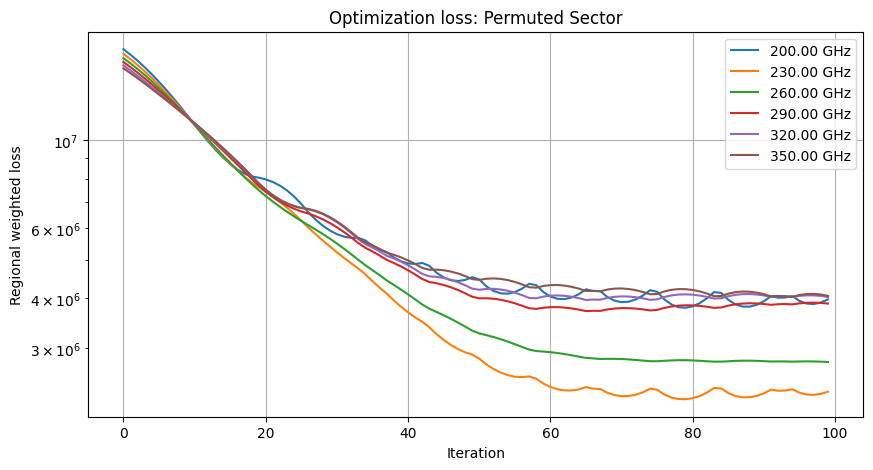


Optimizing: 1st Freq (200 GHz)
Iteration 100/100 | Mean Loss: 3.45377e+06 | Worst Loss: 4.22426e+06


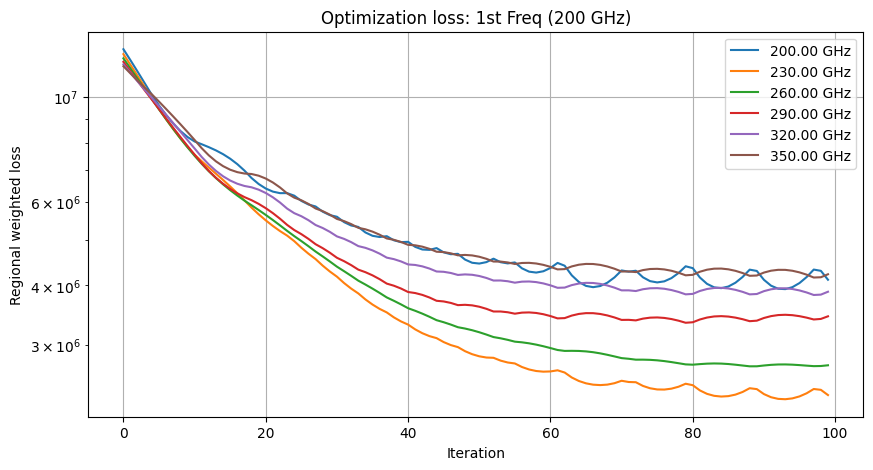


Optimizing: Last Freq (350 GHz)
Iteration 100/100 | Mean Loss: 3.52100e+06 | Worst Loss: 4.14266e+06


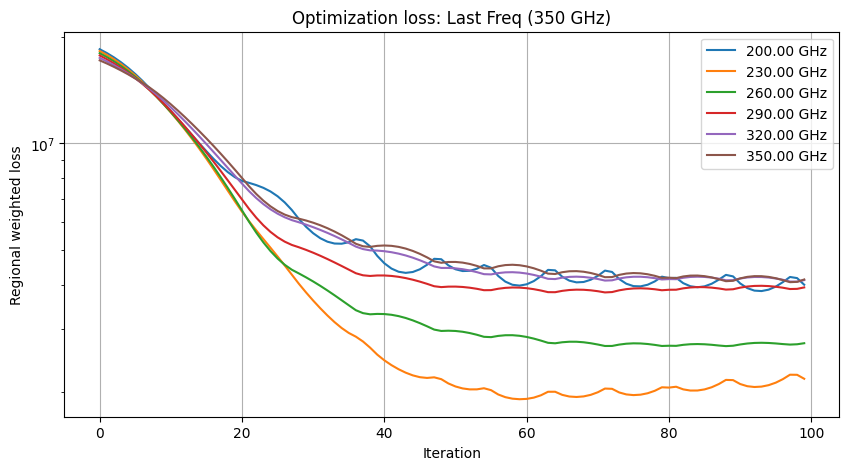


Optimizing: Random Guess
Iteration 100/100 | Mean Loss: 3.45966e+06 | Worst Loss: 3.52755e+06


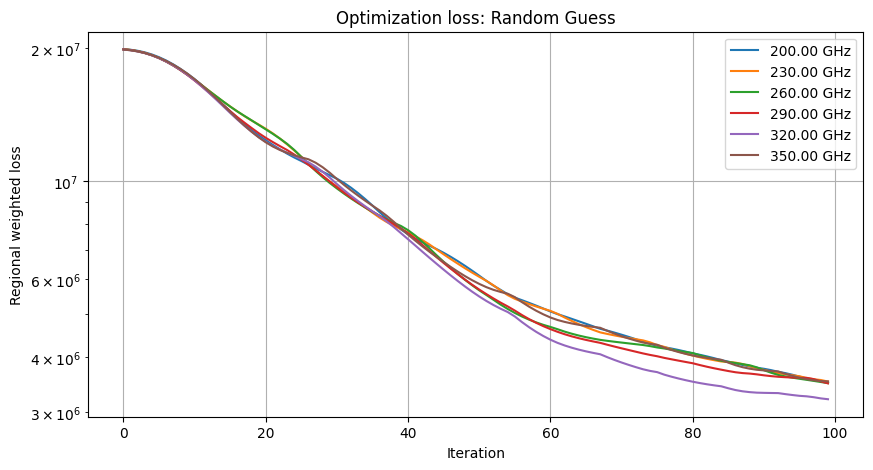


Optimization Complete.


In [27]:

# ==========================================
# PROGRAM 2: PYTORCH MULTI-FREQUENCY OPTIMIZATION
# WITH REGIONAL WEIGHTED LOSS
# ==========================================

print("\nStarting multi-frequency PyTorch Optimization...")

dx = params['rmax'] / params['N']
shape = 2 * params['N'] - 1

torchoptics.set_default_spacing(dx)


# ==========================================
# 1. SOURCE AND TARGET PROFILES
# ==========================================

source_profile = gaussian(
    shape,
    waist_radius=params['w0']
).to(device, dtype=torch.float32)

target_profile = circle(
    shape,
    radius=params['wgoal']
).to(device, dtype=torch.float32)

target_mask = (target_profile > 0).to(torch.float32)


# Match target power to incident beam power
P_in = torch.sum(torch.abs(source_profile) ** 2)
P_tgt = torch.sum(target_mask)

I_tgt = (target_mask * (P_in / P_tgt)).to(torch.float32)


# ==========================================
# 2. DEFINE SPATIAL REGIONS
# ==========================================

# Spatial coordinates
coords = (
    torch.arange(shape, device=device, dtype=torch.float32)
    - (shape - 1) / 2
) * dx

X, Y = torch.meshgrid(coords, coords, indexing='ij')

R = torch.sqrt(X**2 + Y**2)


# Central region: inner disk
center_radius = 0.5 * params['wgoal']

center_mask = (R <= center_radius).float()

# Outer region: annulus between center and target radius
outer_mask = (
    (R > center_radius) &
    (R <= params['wgoal'])
).float()

# Background: everything outside the target circle
background_mask = (R > params['wgoal']).float()


# ==========================================
# 3. REGIONAL LOSS FUNCTION
# ==========================================

# Spatial importance weights
w_center = 0.2
w_outer = 0.6
w_background = 0.2


def regional_loss(I_out, I_target):

    # Center region MSE
    loss_center = torch.sum(
        center_mask * (I_out - I_target)**2
    ) / torch.sum(center_mask)

    # Outer region MSE
    loss_outer = torch.sum(
        outer_mask * (I_out - I_target)**2
    ) / torch.sum(outer_mask)

    # Background region MSE
    loss_background = torch.sum(
        background_mask * (I_out - I_target)**2
    ) / torch.sum(background_mask)

    # Weighted combination
    loss = (
        w_center * loss_center
        + w_outer * loss_outer
        + w_background * loss_background
    )

    return loss


# ==========================================
# 4. FREQUENCY TRANSFER FUNCTIONS
# ==========================================

frequencies = [f0 + i * 30 * 1e9 for i in range(6)]

H_fws = []

fx = fft.fftfreq(
    shape, d=dx, device=device
).to(torch.float32)

fy = fft.fftfreq(
    shape, d=dx, device=device
).to(torch.float32)

FX, FY = torch.meshgrid(fx, fy, indexing='ij')


for f in frequencies:

    lam_f = 3e8 / f

    term = 1 - (lam_f * FX)**2 - (lam_f * FY)**2

    mask = term >= 0

    phase_term = (
        2 * torch.pi * params['fl'] / lam_f
        * torch.sqrt(torch.clamp(term, min=0))
    )

    H_fws.append(
        (torch.exp(1j * phase_term.to(torch.float32)) * mask)
        .to(torch.complex64)
    )


# ==========================================
# 5. OPTIMIZATION PARAMETERS
# ==========================================

optimized_phases = []
optimized_outputs = []
optimized_outputs_2 = []
optimized_freq_outputs = []
optimized_freq_2_outputs = []

# Worst-frequency importance
rho = 0.5

num_iterations = 100

learning_rate = 0.05


# ==========================================
# 6. MULTI-FREQUENCY DOE OPTIMIZATION
# ==========================================

# BASE LENS SUPPRESSED
# The DOE must learn the focusing power entirely on its own.

for init_doe, title in zip(initial_DOEs, titles):

    print(f"\nOptimizing: {title}")

    # Initialize DOE phase
    initial_phase = torch.tensor(
        init_doe,
        device=device,
        dtype=torch.float32
    )

    phi = torch.nn.Parameter(initial_phase.clone())

    # Adam optimizer
    optimizer = torch.optim.Adam(
        [phi],
        lr=learning_rate
    )

    # Store loss evolution
    loss_history = []


    for it in range(num_iterations):

        optimizer.zero_grad()

        # Input field is identical for all frequencies
        E1 = (
            source_profile * torch.exp(1j * phi)
        ).to(torch.complex64)

        losses = []

        # ----------------------------------
        # Propagation at all frequencies
        # ----------------------------------

        for f_idx in range(len(frequencies)):

            E2 = fft.ifft2(
                fft.fft2(E1) * H_fws[f_idx]
            )

            I_out = torch.abs(E2)**2

            # Regional weighted loss
            loss_f = regional_loss(
                I_out.float(),
                I_tgt
            )

            losses.append(loss_f)


        # ----------------------------------
        # Multi-frequency loss
        # ----------------------------------

        losses = torch.stack(losses)

        # Average loss across frequencies
        mean_loss = torch.mean(losses)

        # Worst-performing frequency
        worst_loss = torch.max(losses)

        # Combined objective
        loss = (
            (1 - rho) * mean_loss
            + rho * worst_loss
        )


        # ----------------------------------
        # Backpropagation and optimization
        # ----------------------------------

        loss.backward()

        optimizer.step()

        loss_history.append(losses.detach().cpu().numpy())


        # ----------------------------------
        # Progress information
        # ----------------------------------

        if (it + 1) % 100 == 0:

            print(
                f"Iteration {it + 1}/{num_iterations} | "
                f"Mean Loss: {mean_loss.item():.5e} | "
                f"Worst Loss: {worst_loss.item():.5e}"
            )


    # ======================================
    # 7. STORE OPTIMIZED DOE
    # ======================================

    optimized_phases.append(
        phi.detach().cpu().numpy()
    )


    # ======================================
    # 8. CALCULATE FINAL OUTPUT INTENSITIES
    # ======================================

    avg_I = torch.zeros(
        (shape, shape),
        device=device,
        dtype=torch.float32
    )

    freq_Is = []

    with torch.no_grad():

        E1 = (
            source_profile * torch.exp(1j * phi)
        ).to(torch.complex64)

        for f_idx in range(len(frequencies)):

            E2 = fft.ifft2(
                fft.fft2(E1) * H_fws[f_idx]
            )

            I_f = torch.abs(E2)**2

            freq_Is.append(
                I_f.cpu().numpy()
            )

            avg_I += I_f


    avg_I /= len(frequencies)

    optimized_outputs.append(
        avg_I.cpu().numpy()
    )

    optimized_freq_outputs.append(freq_Is)
    
    # ======================================
    # 8.2  CALCULATE FINAL OUTPUT INTENSITIES
    # ======================================
    
    frequencies_2 = [f0 +15 * 1e9  + i * 30 * 1e9 for i in range(6)]

    avg_I_2 = torch.zeros(
        (shape, shape),
        device=device,
        dtype=torch.float32
    )

    freq_2_Is = []

    with torch.no_grad():

        E1 = (
            source_profile * torch.exp(1j * phi)
        ).to(torch.complex64)

        for f_idx in range(len(frequencies_2)):

            E2 = fft.ifft2(
                fft.fft2(E1) * H_fws[f_idx]
            )

            I_f = torch.abs(E2)**2

            freq_Is.append(
                I_f.cpu().numpy()
            )

            avg_I_2 += I_f


    avg_I_2 /= len(frequencies)

    optimized_outputs_2.append(
        avg_I_2.cpu().numpy()
    )

    optimized_freq_2_outputs.append(freq_Is)


    # ======================================
    # 9. PLOT LOSS EVOLUTION
    # ======================================

    loss_history = np.array(loss_history)

    plt.figure(figsize=(10, 5))

    for i, f in enumerate(frequencies):

        plt.semilogy(
            loss_history[:, i],
            label=f'{f/1e9:.2f} GHz'
        )

    plt.xlabel('Iteration')
    plt.ylabel('Regional weighted loss')
    plt.title(f'Optimization loss: {title}')
    plt.legend()
    plt.grid()
    plt.show()


print("\nOptimization Complete.")

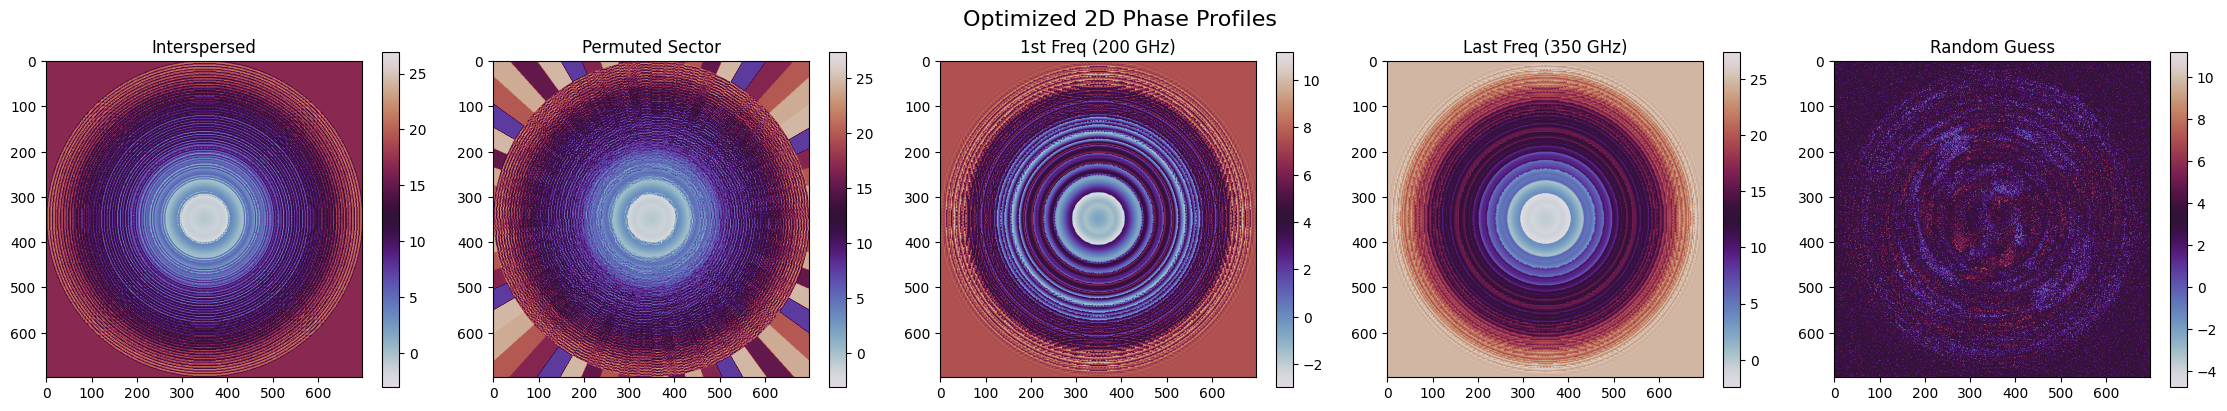

In [23]:
# ==========================================
# PLOTTING RESULTS
# ==========================================

# 1. Plot the Final Optimized Lens Phases (Dynamic width based on number of items)
num_lenses = len(titles)
fig1, axes1 = plt.subplots(1, num_lenses, figsize=(4.5 * num_lenses, 4))
for ax, phase, title in zip(axes1, optimized_phases, titles):
    im = ax.imshow(phase, cmap='twilight')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
fig1.suptitle("Optimized 2D Phase Profiles", fontsize=16)
plt.tight_layout()
plt.show()

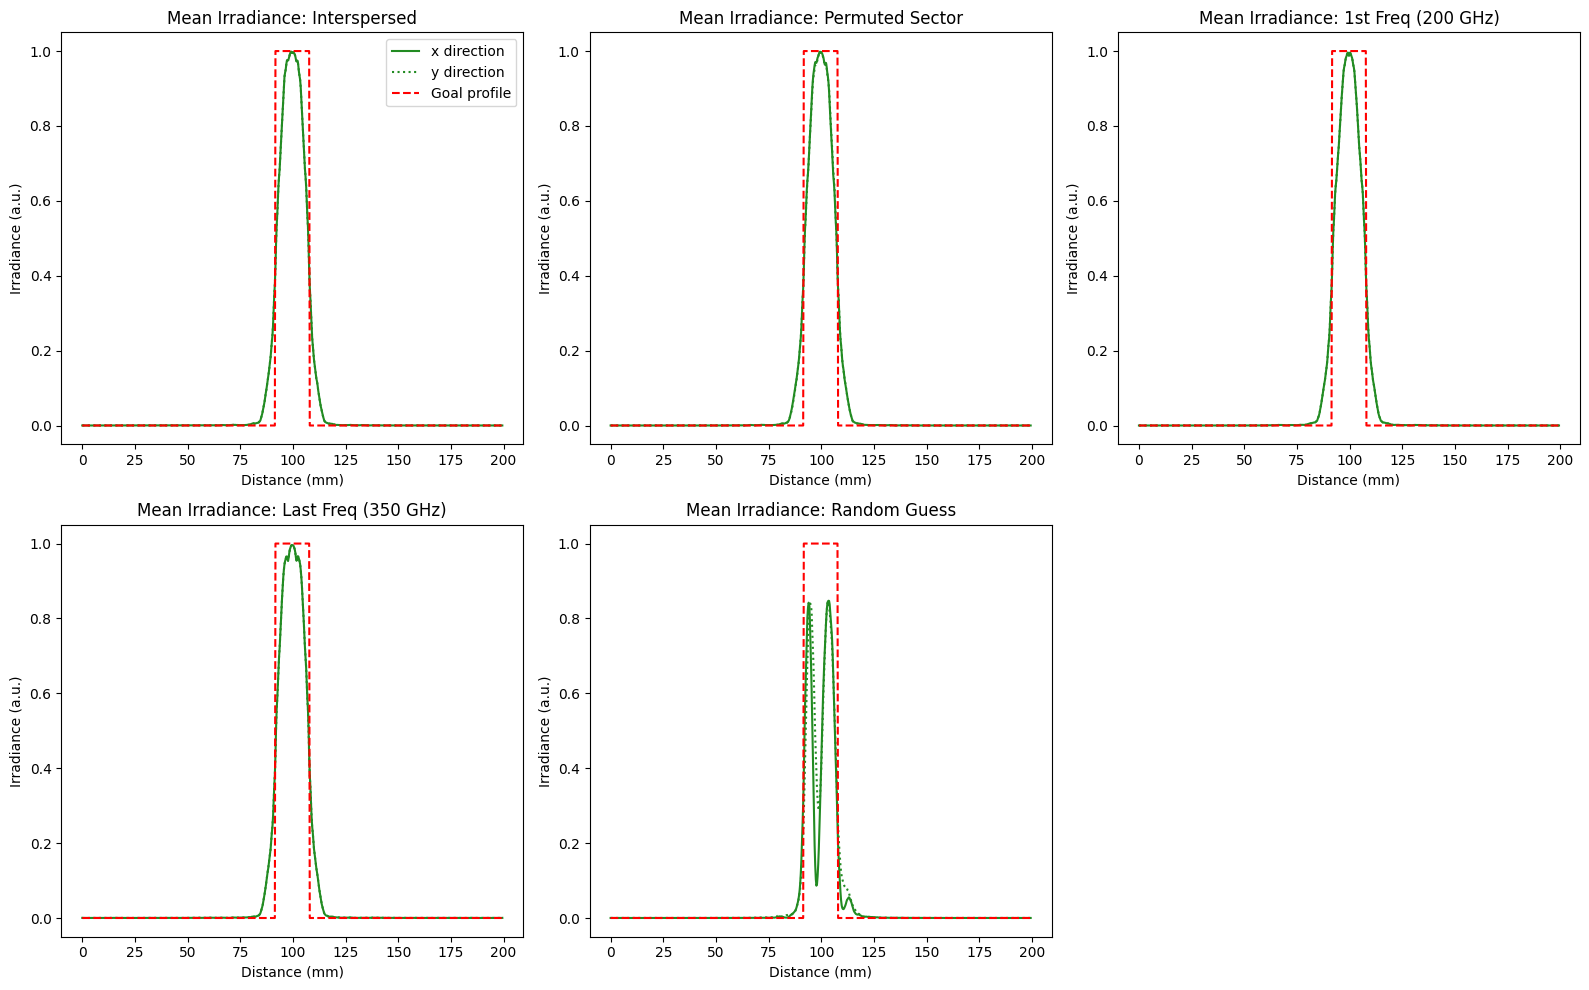

In [28]:
# 2. Plot the Cross-Section Irradiances (Averaged across frequencies in a 2x3 grid)
fig2, axes2 = plt.subplots(2, 3, figsize=(16, 10))
axes2 = axes2.flatten()

# Turn off the empty final axis (since we have 5 items in a 6-slot grid)
for j in range(num_lenses, len(axes2)):
    axes2[j].axis('off')

center_idx = params['N'] - 1
distance_mm = np.arange(shape) * dx * 1000  # meters to mm
center_pos_mm = distance_mm[center_idx]
waist_mm = params["wgoal"] * 1000  # meters to mm
goal_profile = np.where(np.abs(distance_mm - center_pos_mm) <= waist_mm, 1.0, 0.0)

for i, (avg_I, title) in enumerate(zip(optimized_outputs, titles)):
    I_norm = avg_I / np.max(avg_I)
    x_slice = I_norm[center_idx, :]
    y_slice = I_norm[:, center_idx]

    ax = axes2[i]
    ax.plot(distance_mm, x_slice, color='forestgreen', linestyle='-', label='x direction')
    ax.plot(distance_mm, y_slice, color='forestgreen', linestyle=':', label='y direction')
    ax.plot(distance_mm, goal_profile, color='red', linestyle='--', linewidth=1.5, label='Goal profile')

    ax.set_title(f"Mean Irradiance: {title}")
    ax.set_xlabel("Distance (mm)")
    ax.set_ylabel("Irradiance (a.u.)")
    if i == 0:
        ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

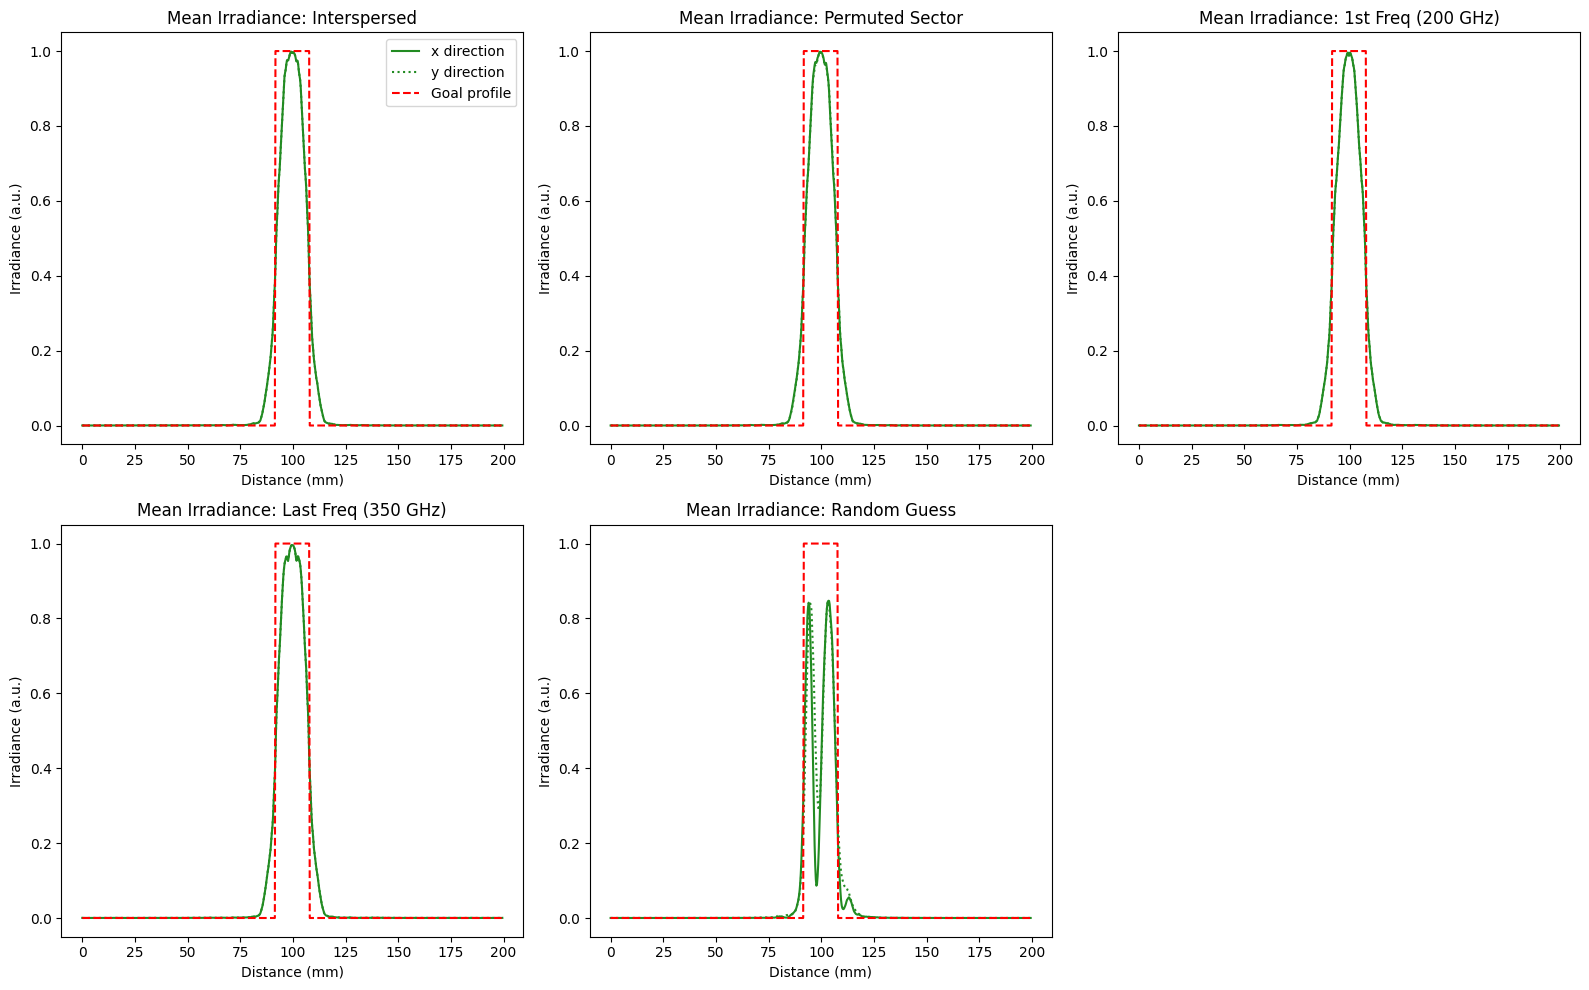

In [29]:
# 2. Plot the Cross-Section Irradiances (Averaged across frequencies in a 2x3 grid)
fig2, axes2 = plt.subplots(2, 3, figsize=(16, 10))
axes2 = axes2.flatten()

# Turn off the empty final axis (since we have 5 items in a 6-slot grid)
for j in range(num_lenses, len(axes2)):
    axes2[j].axis('off')

center_idx = params['N'] - 1
distance_mm = np.arange(shape) * dx * 1000  # meters to mm
center_pos_mm = distance_mm[center_idx]
waist_mm = params["wgoal"] * 1000  # meters to mm
goal_profile = np.where(np.abs(distance_mm - center_pos_mm) <= waist_mm, 1.0, 0.0)

for i, (avg_I_2, title) in enumerate(zip(optimized_outputs_2, titles)):
    I_norm = avg_I_2 / np.max(avg_I_2)
    x_slice = I_norm[center_idx, :]
    y_slice = I_norm[:, center_idx]

    ax = axes2[i]
    ax.plot(distance_mm, x_slice, color='forestgreen', linestyle='-', label='x direction')
    ax.plot(distance_mm, y_slice, color='forestgreen', linestyle=':', label='y direction')
    ax.plot(distance_mm, goal_profile, color='red', linestyle='--', linewidth=1.5, label='Goal profile')

    ax.set_title(f"Mean Irradiance: {title}")
    ax.set_xlabel("Distance (mm)")
    ax.set_ylabel("Irradiance (a.u.)")
    if i == 0:
        ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


Generating per-frequency plots...


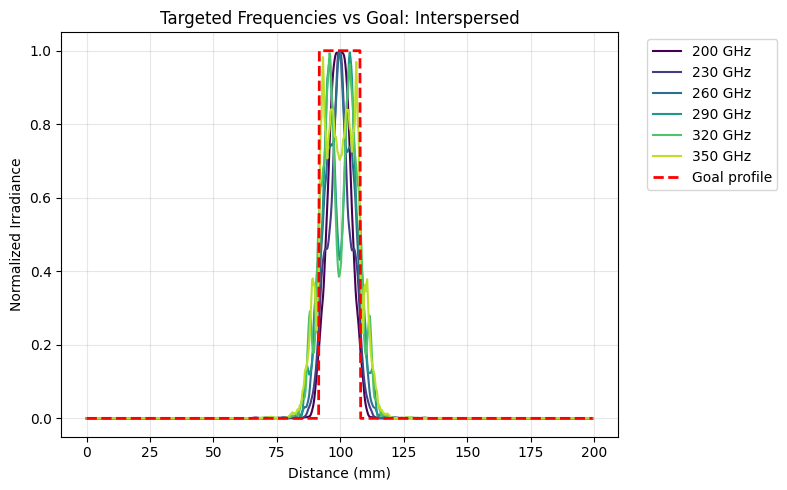

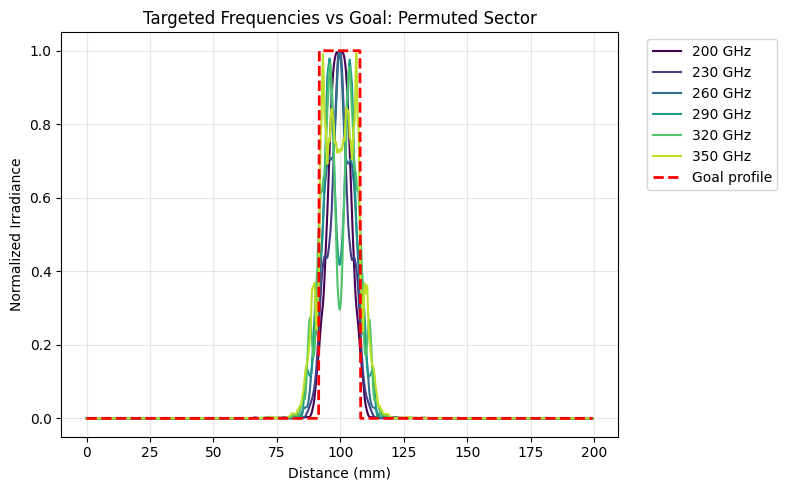

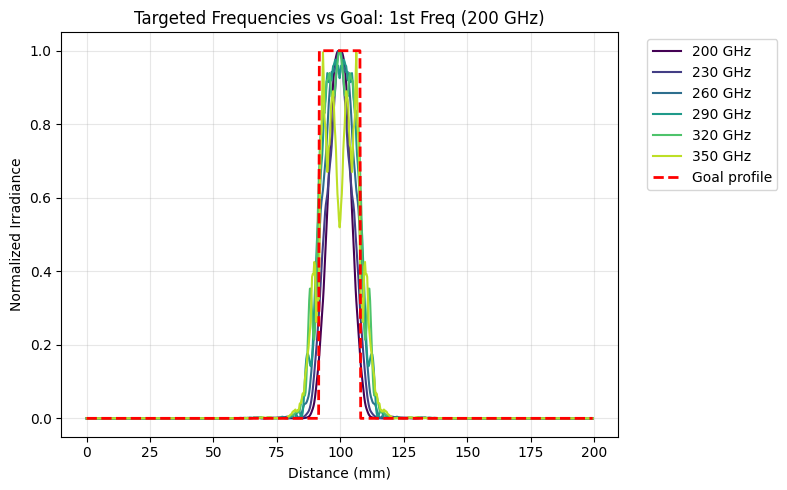

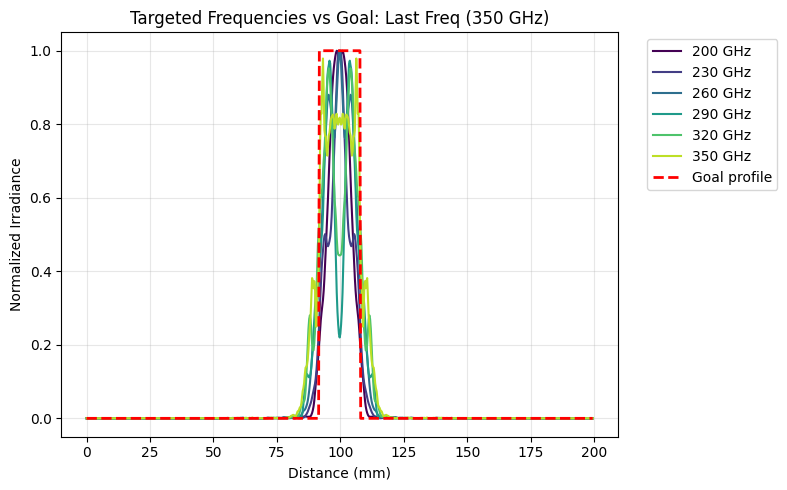

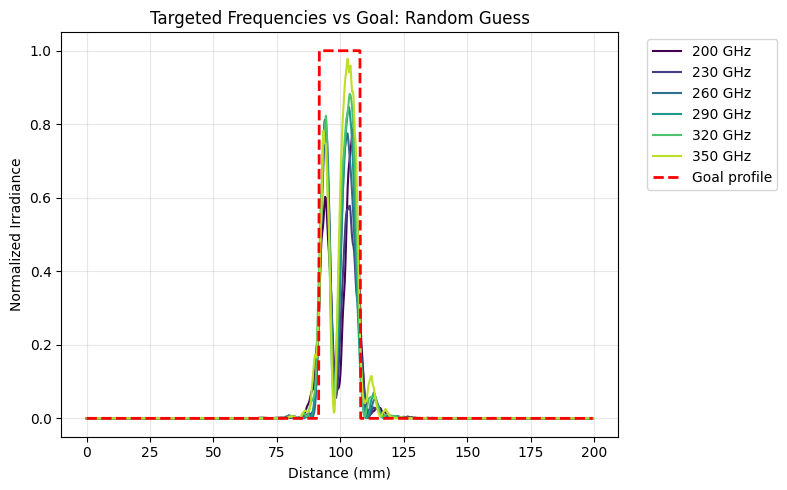

In [30]:
# 3. Plot the Per-Frequency Irradiances for each Lens
# (Requires matplotlib.cm, which is included in standard matplotlib)

print("\nGenerating per-frequency plots...")

for lens_idx, (freq_outputs, title) in enumerate(zip(optimized_freq_outputs, titles)):
    plt.figure(figsize=(8, 5))

    # Generate distinct colors for each frequency using a colormap
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(frequencies)))

    # Plot each frequency's cross-section
    for f_idx, (freq_I, freq_val) in enumerate(zip(freq_outputs, frequencies)):
        I_norm = freq_I / np.max(freq_I)  # Normalize each frequency to its own peak
        x_slice = I_norm[center_idx, :]

        # Using x-slice only to prevent the plot from becoming unreadable with 12+ lines
        plt.plot(distance_mm, x_slice, color=colors[f_idx],
                 label=f'{freq_val / 1e9:.0f} GHz')

    # Plot the Goal Profile
    plt.plot(distance_mm, goal_profile, color='red', linestyle='--',
             linewidth=2, label='Goal profile', zorder=10)

    plt.title(f"Targeted Frequencies vs Goal: {title}")
    plt.xlabel("Distance (mm)")
    plt.ylabel("Normalized Irradiance")

    # Place legend outside the plot so it doesn't cover the beam profile
    plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


Generating per-frequency plots...


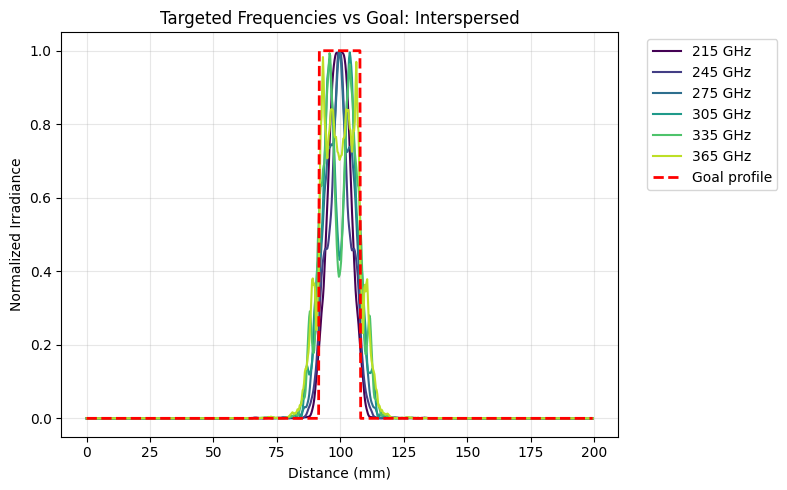

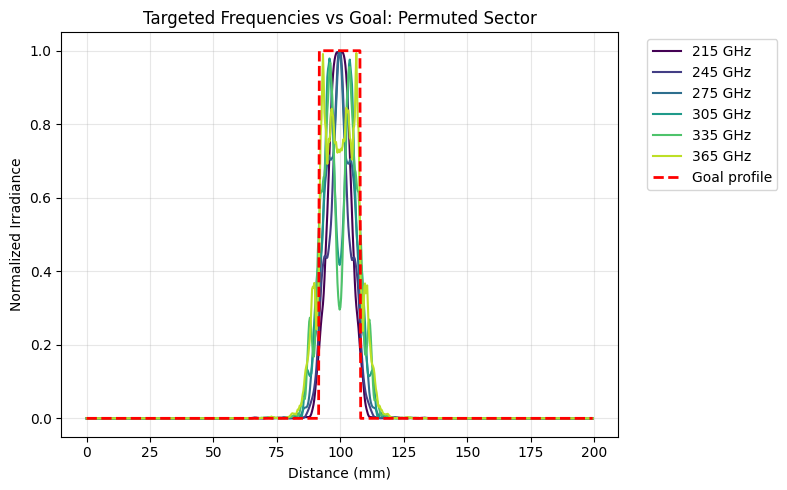

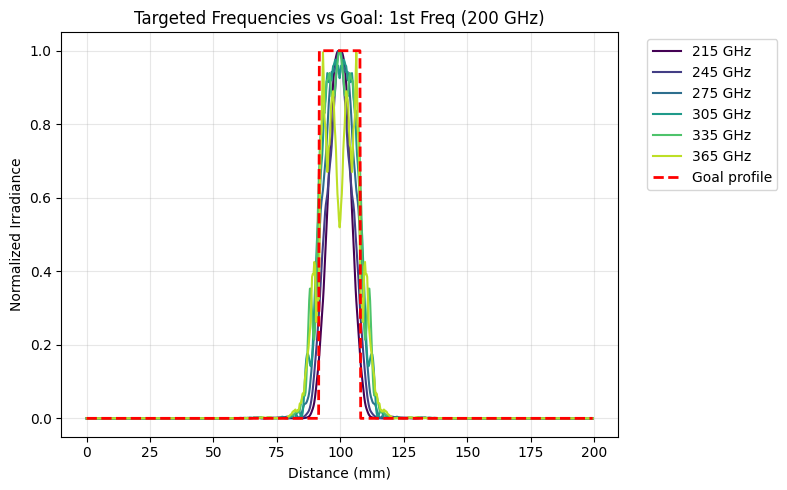

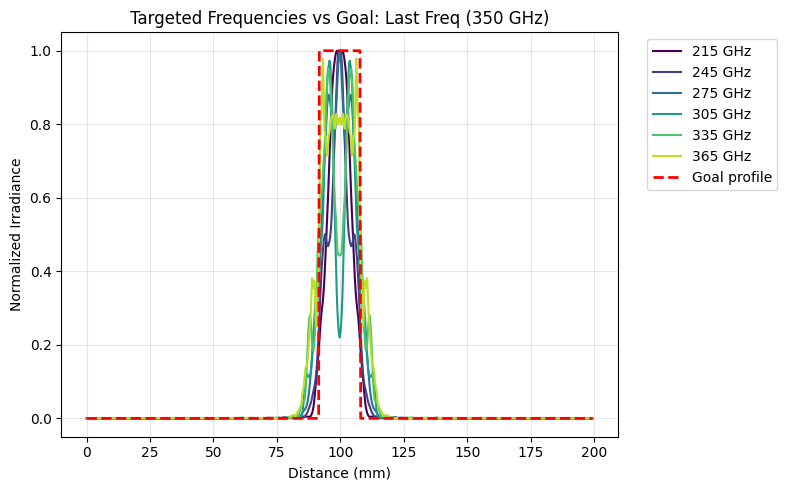

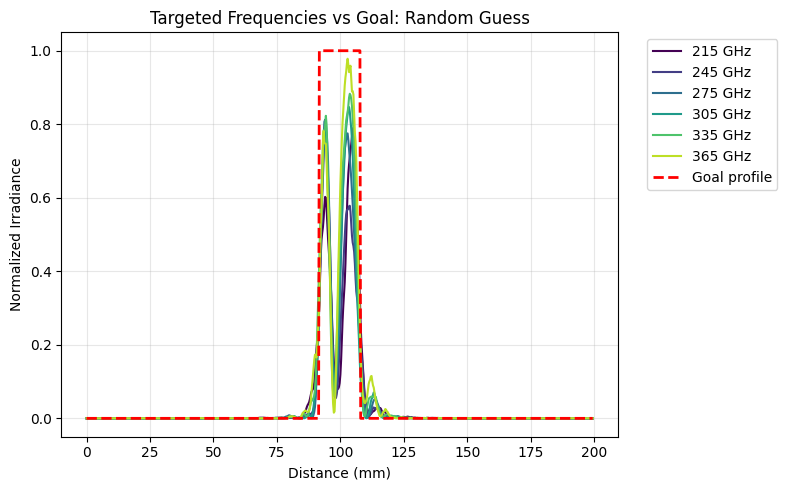

In [31]:
# 3. Plot the Per-Frequency Irradiances for each Lens
# (Requires matplotlib.cm, which is included in standard matplotlib)

print("\nGenerating per-frequency plots...")

for lens_idx, (freq_2_outputs, title) in enumerate(zip(optimized_freq_2_outputs, titles)):
    plt.figure(figsize=(8, 5))

    # Generate distinct colors for each frequency using a colormap
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(frequencies_2)))

    # Plot each frequency's cross-section
    for f_idx, (freq_I, freq_val) in enumerate(zip(freq_2_outputs, frequencies_2)):
        I_norm = freq_I / np.max(freq_I)  # Normalize each frequency to its own peak
        x_slice = I_norm[center_idx, :]

        # Using x-slice only to prevent the plot from becoming unreadable with 12+ lines
        plt.plot(distance_mm, x_slice, color=colors[f_idx],
                 label=f'{freq_val / 1e9:.0f} GHz')

    # Plot the Goal Profile
    plt.plot(distance_mm, goal_profile, color='red', linestyle='--',
             linewidth=2, label='Goal profile', zorder=10)

    plt.title(f"Targeted Frequencies vs Goal: {title}")
    plt.xlabel("Distance (mm)")
    plt.ylabel("Normalized Irradiance")

    # Place legend outside the plot so it doesn't cover the beam profile
    plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()